<a href="https://colab.research.google.com/github/Deshawa77/pusl3123-a1/blob/main/00_setup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount("/content/drive")

import os
PROJECT = "/content/drive/MyDrive/pusl3123-a1"
os.chdir(PROJECT)
print("Working directory:", os.getcwd())
print(os.listdir("."))

Mounted at /content/drive
Working directory: /content/drive/MyDrive/pusl3123-a1
['results', 'figures', '00_setup.ipynb']


In [2]:
import sys, random, json, time, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

print("Python      ", sys.version.split()[0])
print("torch       ", torch.__version__)
print("torchvision ", torchvision.__version__)
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("CUDA        ", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

Python       3.13.16
torch        2.14.1+cu130
torchvision  0.29.1+cu130
numpy        2.4.6
pandas       2.2.3
CUDA         True Tesla T4


In [3]:
def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)
print("device:", device)

device: cuda


In [5]:
DATA_ROOT = "/content/data"
raw_train = torchvision.datasets.CIFAR10(DATA_ROOT, train=True,  download=True)
raw_test  = torchvision.datasets.CIFAR10(DATA_ROOT, train=False, download=True)
classes = raw_train.classes
print(len(raw_train), len(raw_test))                 # 50000 10000
print("class counts:", np.bincount(raw_train.targets))  # 5000 each

50000 10000
class counts: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


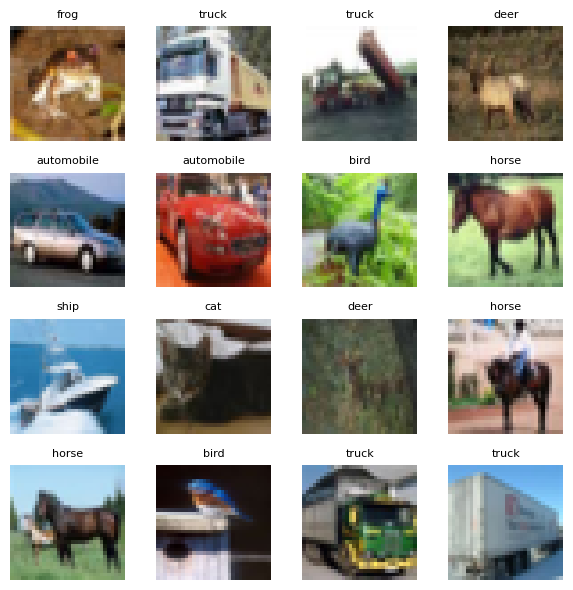

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, i in zip(axes.flat, range(16)):
    img, label = raw_train[i]
    ax.imshow(img); ax.set_title(classes[label], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig("figures/cifar_samples.png", dpi=200); plt.show()

In [7]:
rng = np.random.default_rng(42)
perm = rng.permutation(50000)
train_idx, val_idx = perm[:45000], perm[45000:]
#np.save("split.npy", perm)                       # saved into Drive, shared by every notebook

targets = np.array(raw_train.targets)
assert len(train_idx) == 45000 and len(val_idx) == 5000
assert len(set(train_idx) & set(val_idx)) == 0
print("val class counts:", np.bincount(targets[val_idx]))

val class counts: [453 480 514 525 491 517 560 476 491 493]


In [8]:
x = raw_train.data[train_idx].astype(np.float32) / 255.0
MEAN = tuple(float(m) for m in x.mean(axis=(0, 1, 2)))
STD  = tuple(float(s) for s in x.std(axis=(0, 1, 2)))
print("MEAN =", MEAN); print("STD  =", STD)

MEAN = (0.49181848764419556, 0.4826730489730835, 0.44718557596206665)
STD  = (0.246906116604805, 0.2434273362159729, 0.2615409195423126)
